# Assignment 12: Logistic Regression - Predicting Online Purchases

In this assignment, I will use logistic regression to predict whether a visitor to an online store will make a purchase during their session. I used the Online Shoppers Purchasing Intention dataset from the UCI Machine Learning Repository instead of the Titanic dataset (with my instructor's permission), because it is real Google Analytics session data and connects to my background in digital marketing.

The target is Revenue (True = the session ended in a purchase). Like the Titanic data, the classes are imbalanced: most visitors do not buy. This makes it a good dataset for learning why accuracy alone can be misleading.

My steps:
- Load the data, check its structure, remove duplicates, and split it into training and test sets
- Explore the training data
- Prepare the data: handle missing values, encode categories, and scale the features
- Train a baseline logistic regression model and evaluate it with a confusion matrix and classification report
- Experiment with hyperparameters (C, penalty, solver, class_weight) and the decision threshold
- Predict for a new session and interpret the results, including odds ratios

## Step 1: Load the Dataset and Check Its Structure

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay)


In [2]:
pd.set_option("display.max_columns", None)

In [3]:
shop = pd.read_csv("online_shoppers_intention.csv")
print("Shape:", shop.shape)
display(shop.head())

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
print("\nData types:")
print(shop.dtypes)


Data types:
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object


In [5]:
print("\nUnique values per column:")
print(shop.nunique())


Unique values per column:
Administrative               27
Administrative_Duration    3335
Informational                17
Informational_Duration     1258
ProductRelated              311
ProductRelated_Duration    9551
BounceRates                1872
ExitRates                  4777
PageValues                 2704
SpecialDay                    6
Month                        10
OperatingSystems              8
Browser                      13
Region                        9
TrafficType                  20
VisitorType                   3
Weekend                       2
Revenue                       2
dtype: int64


In [6]:
print("\nMissing values:", shop.isnull().sum().sum())
print("Duplicate rows:", shop.duplicated().sum())


Missing values: 0
Duplicate rows: 125


In [7]:
print("\nTarget (Revenue):")
print(shop["Revenue"].value_counts())
print((shop["Revenue"].value_counts(normalize=True) * 100).round(1))


Target (Revenue):
Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.5
True     15.5
Name: proportion, dtype: float64


### Interpretation

The dataset has 12,330 website sessions and 18 columns. Each row is one visit to an online store, recorded with Google Analytics. The target is Revenue: True means the visit ended in a purchase.

What the columns represent:
- Page activity: Administrative (account pages), Informational (pages like "about us" or shipping information), and ProductRelated (product pages), each with the number of pages visited and the total time spent on them in seconds.
- Google Analytics metrics: BounceRates (how often visitors leave after viewing only one page), ExitRates (how often a page is the last one viewed), and PageValues (the average value of the pages visited, based on how often they come before a purchase).
- Timing: SpecialDay (how close the visit was to a holiday such as Valentine's Day), Month, and Weekend.
- Visitor information: VisitorType (new or returning), and OperatingSystems, Browser, Region, and TrafficType.

Data types:
- Month and VisitorType are text, and Weekend and Revenue are True/False, so they will need to be converted into numbers.
- OperatingSystems, Browser, Region, and TrafficType are stored as numbers, but they are actually category codes. The real names were replaced with numbers, so a higher number does not mean "more". I will treat them as categories, not as amounts.
- Month has only 10 unique values, because January and April are not in the data.

Structure checks:
- There are no missing values.
- There are 125 duplicate rows, which I will remove before splitting, so the same session cannot appear in both the training and test sets.

Target:
- 10,422 sessions (84.5%) did not end in a purchase, and only 1,908 (15.5%) did.
- The classes are imbalanced. A model that always predicted "no purchase" would already be 84.5% accurate while never finding a single buyer, so accuracy alone will not be a good measure. I will focus on precision, recall, F1-score, and ROC-AUC.

## Step 2: Remove Duplicates and Split the Data

In [8]:
shop = shop.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", shop.shape)

Shape after removing duplicates: (12205, 18)


In [9]:
X = shop.drop(columns="Revenue")
y = shop["Revenue"].astype(int) 

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [11]:
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nBuyers in train (%):", round(y_train.mean() * 100, 1), "| in test (%):", round(y_test.mean() * 100, 1))

X_train: (9764, 17) | X_test: (2441, 17)

Buyers in train (%): 15.6 | in test (%): 15.6


### Interpretation

I removed the 125 duplicate rows, leaving 12,205 sessions. I converted the target (Revenue) from True/False into 1/0, and separated the 17 features from the target.

I split the data into 80% training (9,764 sessions) and 20% testing (2,441 sessions), using stratify. Both sets have exactly 15.6% buyers, so the test set fairly represents the imbalance in the data. From now on, I explore and prepare the data using only the training set.

## Step 3: Exploratory Data Analysis (Training Data)

In [12]:
train = X_train.copy()
train["Revenue"] = y_train

In [13]:
display(train.describe().round(2))
print("Categorical features:")
display(train[["Month", "VisitorType", "Weekend"]].describe())

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Revenue
count,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00,9764.00
mean,2.34,82.22,0.51,34.95,32.10,1207.26,0.02,0.04,5.95,0.06,2.13,2.37,3.13,4.06,0.16
std,3.35,179.50,1.28,143.83,44.82,1926.39,0.05,0.05,18.86,0.20,0.91,1.73,2.39,4.03,0.36
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,0.00
25%,0.00,0.00,0.00,0.00,8.00,193.47,0.00,0.01,0.00,0.00,2.00,2.00,1.00,2.00,0.00
50%,1.00,9.00,0.00,0.00,18.00,617.00,0.00,0.02,0.00,0.00,2.00,2.00,3.00,2.00,0.00
75%,4.00,94.72,0.00,0.00,39.00,1483.65,0.02,0.05,0.00,0.00,3.00,2.00,4.00,4.00,0.00
max,27.00,3398.75,24.00,2549.38,705.00,63973.52,0.20,0.20,361.76,1.00,8.00,13.00,9.00,20.00,1.00


Categorical features:


,Month,VisitorType,Weekend
count,9764,9764,9764
unique,10,3,2
top,May,Returning_Visitor,False
freq,2674,8347,7480


In [14]:
print("\nSkewness of numeric features:")
num_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues"]
print(train[num_cols].skew().round(2).sort_values(ascending=False))


Skewness of numeric features:
ProductRelated_Duration    7.87
Informational_Duration     7.54
PageValues                 6.55
Administrative_Duration    5.68
ProductRelated             4.39
Informational              4.10
BounceRates                3.17
ExitRates                  2.24
Administrative             1.99
dtype: float64


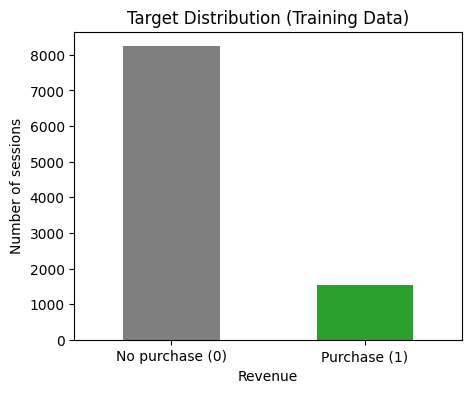

In [15]:
ax = train["Revenue"].value_counts().plot(kind="bar", color=["tab:gray", "tab:green"], figsize=(5, 4))
ax.set_xticklabels(["No purchase (0)", "Purchase (1)"], rotation=0)
ax.set_title("Target Distribution (Training Data)"); ax.set_ylabel("Number of sessions")
plt.show()

### Interpretation: Summary Statistics and Target Distribution

Target: in the training data, about 8,250 sessions did not end in a purchase and about 1,500 did (15.6%). The bar chart shows how much smaller the purchase class is.

Numeric features:
- A typical session views 18 product pages (median) and spends about 617 seconds (about 10 minutes) on them. Most visitors view few account (median 1) or information pages (median 0).
- PageValues has a median of 0, and at least 75% of sessions have a value of 0, meaning most visitors never view pages that usually come before a purchase. The maximum is 361.76.
- BounceRates and ExitRates are small decimals (averages of 0.02 and 0.04).
- All count and duration features are strongly right-skewed, with skewness between 2 and 7.9. For example, ProductRelated_Duration has a median of 617 seconds but a maximum of almost 64,000 seconds (about 17.8 hours). A few sessions with extreme values stretch the scale, so I will apply a log transformation before modelling.

Categorical features:
- May is the most common month (2,674 sessions), most visitors are returning visitors (8,347 of 9,764), and most visits happen on weekdays (7,480).
- OperatingSystems, Browser, Region, and TrafficType appear as numbers in the statistics table, but their means and standard deviations have no meaning, because they are category codes.

In [16]:
for col in ["Month", "VisitorType", "Weekend", "SpecialDay", "TrafficType"]:
    rate = train.groupby(col)["Revenue"].agg(sessions="count", conversion_rate="mean")
    rate["conversion_rate"] = (rate["conversion_rate"] * 100).round(1)
    print(f"\n=== Conversion rate (%) by {col} ===")
    print(rate.sort_values("conversion_rate", ascending=False).to_string())


=== Conversion rate (%) by Month ===
       sessions  conversion_rate
Month                           
Nov        2358             25.4
Oct         433             22.4
Sep         354             18.9
Aug         360             17.2
Jul         353             14.4
Dec        1363             13.1
May        2674             10.7
Mar        1500             10.6
June        225             10.2
Feb         144              2.1

=== Conversion rate (%) by VisitorType ===
                   sessions  conversion_rate
VisitorType                                 
New_Visitor            1349             24.1
Other                    68             23.5
Returning_Visitor      8347             14.2

=== Conversion rate (%) by Weekend ===
         sessions  conversion_rate
Weekend                           
True         2284             17.5
False        7480             15.1

=== Conversion rate (%) by SpecialDay ===
            sessions  conversion_rate
SpecialDay                          

### Interpretation: Conversion Rate by Group

The conversion rate is the percentage of sessions that ended in a purchase.

Month:
- November has the highest conversion rate (25.4%), followed by October (22.4%) and September (18.9%), likely because of holiday shopping and sales like Black Friday.
- February has the lowest conversion rate (2.1%).
- May has the most sessions (2,674) but a low conversion rate (10.7%), so it brings a lot of traffic but relatively few buyers.

Visitor type:
- New visitors convert at 24.1%, much higher than returning visitors (14.2%). This is surprising. Returning visitors may often come back just to browse, compare prices, or check their account. The "Other" group has only 68 sessions, so its rate is less reliable.

Weekend:
- Weekend sessions convert slightly better (17.5%) than weekday sessions (15.1%).

Special day:
- Sessions close to a special day convert much less (3.5% to 8.8%) than sessions on normal days (16.7%). This may be because special days in this data fall around Valentine's Day (February) and Mother's Day (May), which are low-converting months. Visitors may also browse for gift ideas before buying elsewhere.

Traffic type:
- Traffic type 2 is the largest high-performing source (3,111 sessions, 21.5% conversion). Types 1 and 3 bring a lot of traffic but convert at only about 9% to 11%, and type 13 converts at only 6%.
- Several traffic types have very few sessions (for example, types 15 to 19 have between 1 and 31 sessions). Their conversion rates (such as 0% or 34.4%) are not reliable, so I will group rare traffic types into one "Other" category before encoding.

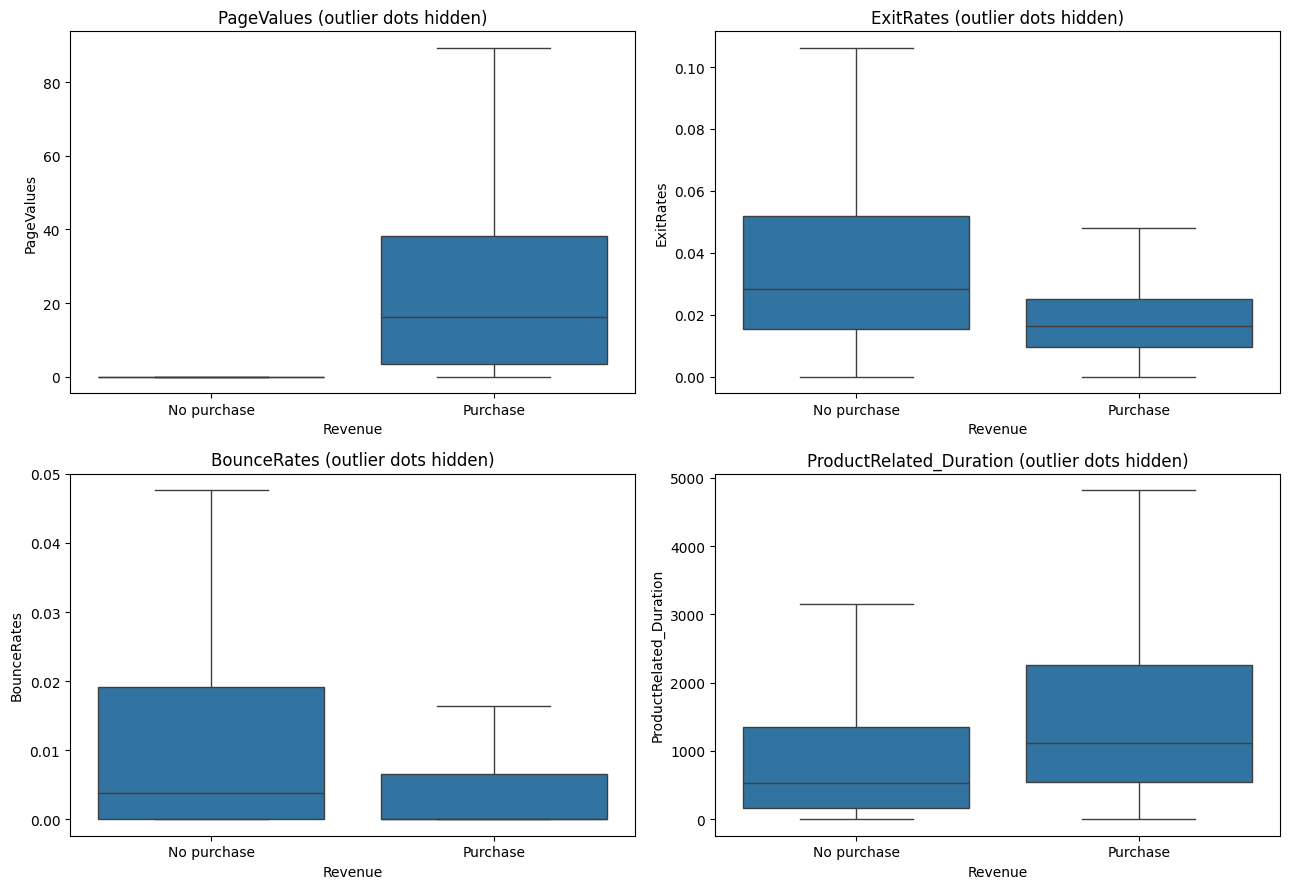

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.flat, ["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration"]):
    sns.boxplot(data=train, x="Revenue", y=col, ax=ax, showfliers=False)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["No purchase", "Purchase"])
    ax.set_title(f"{col} (outlier dots hidden)")
plt.tight_layout(); plt.show()



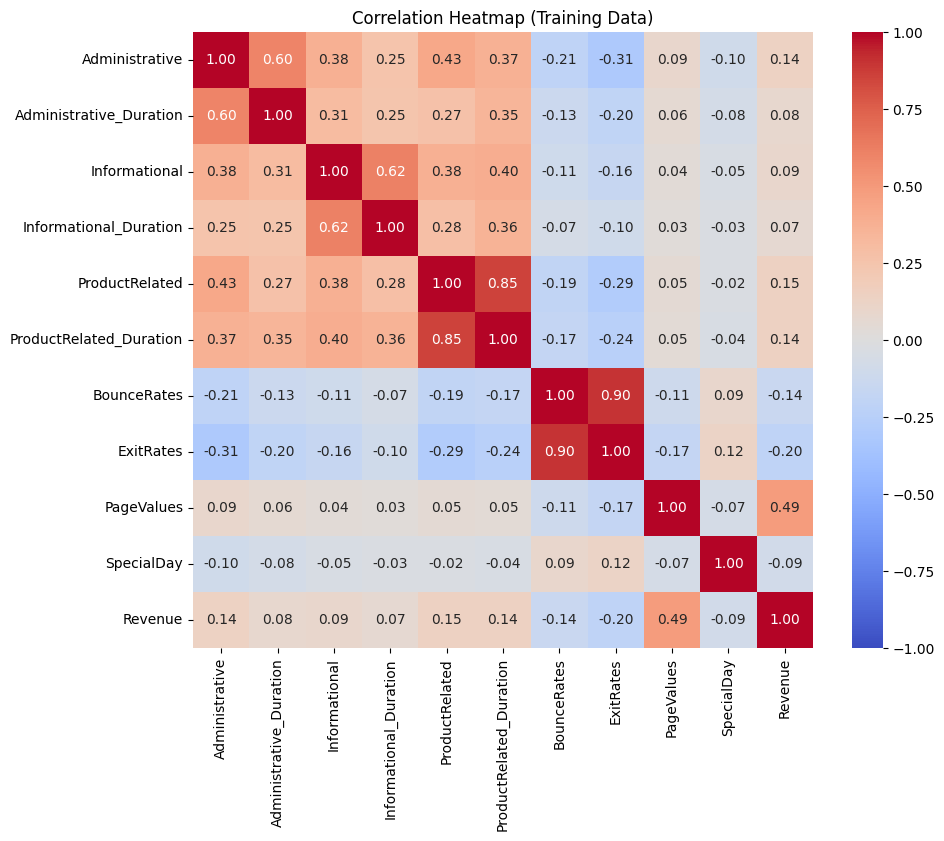

In [19]:
plt.figure(figsize=(10, 8))
sns.heatmap(train[num_cols + ["SpecialDay", "Revenue"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap (Training Data)")
plt.show()

### Interpretation: Buyers vs Non-Buyers and Correlations

Boxplots (outlier dots hidden to show typical sessions):
- PageValues shows the biggest difference. Almost all non-buyers have a PageValue of 0, while buyers have a median of about 16, with the middle half between about 4 and 38. Buyers view pages that usually lead to purchases, such as product and checkout pages.
- ExitRates and BounceRates are lower for buyers. Buyers stay on the site and keep clicking, while non-buyers are more likely to leave quickly.
- Buyers spend more time on product pages (median about 1,100 seconds vs about 500 seconds for non-buyers).

Correlation heatmap:
- PageValues has by far the strongest relationship with purchase (0.49).
- ExitRates (-0.20) and BounceRates (-0.14) have negative relationships: higher exit and bounce rates are linked to fewer purchases.
- Page counts and durations have weak positive relationships (0.07 to 0.15).
- SpecialDay has a weak negative relationship (-0.09), matching the lower conversion rate near holidays.

Multicollinearity:
- BounceRates and ExitRates are very strongly correlated (0.90), so they carry almost the same information.
- ProductRelated and ProductRelated_Duration are also strongly correlated (0.85), because viewing more pages takes more time.
- Since logistic regression coefficients become unreliable when features overlap this much, I will keep ExitRates (the stronger of the two) and drop BounceRates.

Note: PageValues is calculated by Google Analytics using past purchases, so it is very closely linked to the target. I will keep it, but later compare the model with and without it to see how much the model depends on this one feature.

## Step 4: Data Preparation

In [20]:
# 1. Missing values
print("Missing values - train:", X_train.isnull().sum().sum(), "| test:", X_test.isnull().sum().sum())


Missing values - train: 0 | test: 0


In [21]:
# 2. Rare traffic types (fewer than 100 training sessions) -> grouped as "Other", learned from TRAIN only
traffic_counts = X_train["TrafficType"].value_counts()
rare_traffic = traffic_counts[traffic_counts < 100].index.tolist()
print("Rare traffic types grouped as 'Other':", sorted(rare_traffic))

Rare traffic types grouped as 'Other': [7, 9, 14, 15, 16, 17, 18, 19]


In [22]:
log_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "ExitRates", "PageValues"]

def prepare(data):
    data = data.copy()
    # Drop irrelevant / redundant columns
    data = data.drop(columns=["BounceRates", "OperatingSystems", "Browser", "Region"])
    # Group rare traffic types and treat traffic type as a category
    data["TrafficType"] = data["TrafficType"].where(~data["TrafficType"].isin(rare_traffic), "Other").astype(str)
    # True/False -> 1/0
    data["Weekend"] = data["Weekend"].astype(int)
    # Log transform skewed columns (log1p handles zeros)
    for col in log_cols:
        data[col] = np.log1p(data[col])
    # One-hot encode categories
    data = pd.get_dummies(data, columns=["Month", "VisitorType", "TrafficType"], drop_first=True, dtype=int)
    return data


In [23]:
X_train_p = prepare(X_train)
X_test_p = prepare(X_test).reindex(columns=X_train_p.columns, fill_value=0)

In [24]:
print("\nShape after preparation - train:", X_train_p.shape, "| test:", X_test_p.shape)
print("Skewness after log (train):")
print(X_train_p[log_cols].skew().round(2).sort_values(ascending=False))
print("\nColumns:", list(X_train_p.columns))


Shape after preparation - train: (9764, 32) | test: (2441, 32)
Skewness after log (train):
ExitRates                  2.13
Informational              2.01
Informational_Duration     1.91
PageValues                 1.80
Administrative             0.56
Administrative_Duration    0.24
ProductRelated            -0.04
ProductRelated_Duration   -1.43
dtype: float64

Columns: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend', 'Month_Dec', 'Month_Feb', 'Month_Jul', 'Month_June', 'Month_Mar', 'Month_May', 'Month_Nov', 'Month_Oct', 'Month_Sep', 'VisitorType_Other', 'VisitorType_Returning_Visitor', 'TrafficType_10', 'TrafficType_11', 'TrafficType_13', 'TrafficType_2', 'TrafficType_20', 'TrafficType_3', 'TrafficType_4', 'TrafficType_5', 'TrafficType_6', 'TrafficType_8', 'TrafficType_Other']


### Interpretation

There are no missing values in either set, so no imputation was needed.

Changes I made (all values learned from the training data, then applied to both sets):
- Dropped BounceRates (almost identical to ExitRates, correlation 0.90), and OperatingSystems, Browser, and Region (anonymized technical codes with no clear marketing meaning, which would have added many columns with little value).
- Grouped rare traffic types (fewer than 100 training sessions) into one "Other" category, so the model does not learn from groups that are too small to be reliable.
- Converted Weekend from True/False to 1/0.
- Applied a log transformation (log1p) to the page counts, durations, ExitRates, and PageValues to reduce their strong right skew.
- One-hot encoded Month, VisitorType, and TrafficType, with drop_first=True. The baseline categories are August, New_Visitor, and traffic type 1.

Results:
- Both sets now have the same 32 numeric features.
- The log transformation greatly reduced the skew of most columns. For example, ProductRelated went from 4.39 to -0.04, and Administrative_Duration from 5.68 to 0.24.
- ExitRates is still skewed (2.13), because its values are very small decimals (around 0.02 to 0.05), and the log of numbers this close to 1 barely changes them.

The features will be scaled with StandardScaler inside the model Pipeline, because logistic regression's regularization treats all coefficients fairly only when the features are on the same scale.

## Step 5: Train a Baseline Logistic Regression Model and Evaluate It

In [25]:
from sklearn.dummy import DummyClassifier

In [26]:
# "Always predict no purchase" baseline (to show the accuracy trap)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_p, y_train)
print("Always-'no purchase' accuracy:", round(accuracy_score(y_test, dummy.predict(X_test_p)), 3))

Always-'no purchase' accuracy: 0.844



Train accuracy: 0.895
Test accuracy:  0.896
ROC-AUC:        0.921

               precision    recall  f1-score   support

 No purchase       0.93      0.95      0.94      2059
    Purchase       0.70      0.59      0.64       382

    accuracy                           0.90      2441
   macro avg       0.81      0.77      0.79      2441
weighted avg       0.89      0.90      0.89      2441



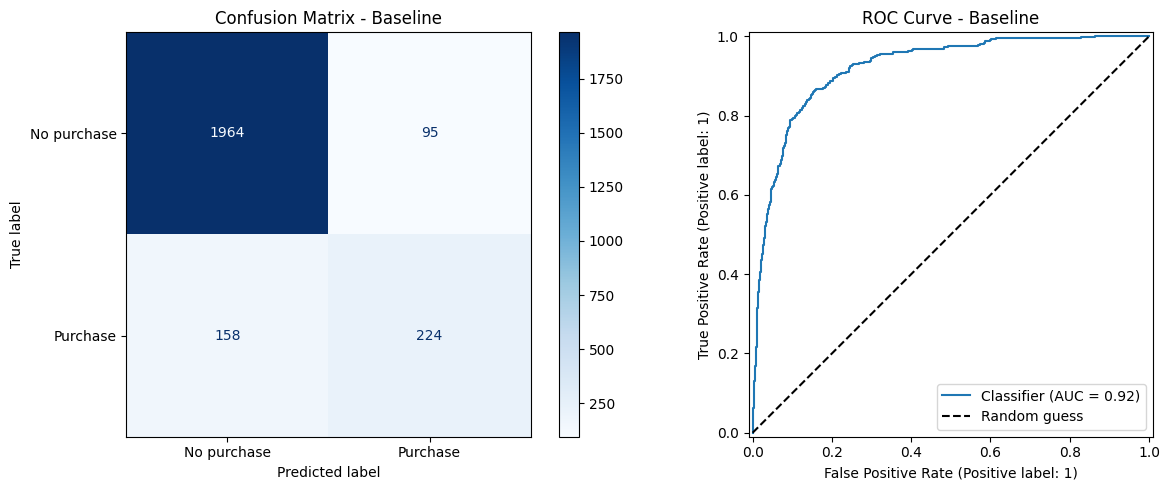

In [28]:
# Baseline logistic regression (default settings)
log_reg = Pipeline([("scaler", StandardScaler()),
                    ("model", LogisticRegression(max_iter=1000, random_state=42))])
log_reg.fit(X_train_p, y_train)

y_pred = log_reg.predict(X_test_p)
y_prob = log_reg.predict_proba(X_test_p)[:, 1]

print("\nTrain accuracy:", round(accuracy_score(y_train, log_reg.predict(X_train_p)), 3))
print("Test accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print("ROC-AUC:       ", round(roc_auc_score(y_test, y_prob), 3))
print("\n", classification_report(y_test, y_pred, target_names=["No purchase", "Purchase"]))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["No purchase", "Purchase"]).plot(cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix - Baseline")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC Curve - Baseline"); axes[1].legend()
plt.tight_layout(); plt.show()

### Interpretation

Accuracy trap:
A model that always predicts "no purchase" reaches 84.4% accuracy on the test set without finding a single buyer. My logistic regression model reached 89.6%, only about 5 percentage points better. This shows why accuracy alone is not a good measure for this imbalanced data.

Overfitting check:
Training accuracy (89.5%) and test accuracy (89.6%) are almost identical, so the model is not overfitting.

Confusion matrix (2,441 test sessions):
- True negatives: 1,964 non-buyers correctly predicted as non-buyers.
- False positives: 95 non-buyers wrongly predicted as buyers. In marketing, this could mean sending a discount or retargeting ad to someone who would not have bought.
- False negatives: 158 buyers wrongly predicted as non-buyers. These are missed opportunities: people who were ready to buy but were not identified.
- True positives: 224 buyers correctly identified.

Classification report:
- No purchase: precision 0.93, recall 0.95, F1 0.94. The model is very good at recognizing non-buyers, because they are the majority.
- Purchase: precision 0.70, recall 0.59, F1 0.64. When the model predicts a purchase, it is right 70% of the time, but it only finds 59% of the actual buyers.
- The macro average F1 (0.79) treats both classes equally and is lower than the weighted average (0.89), which is pulled up by the large no-purchase class.

ROC curve and AUC:
The ROC-AUC is 0.921, which means the model ranks buyers above non-buyers very well across all possible thresholds. The curve rises steeply, far above the random-guess line.

The high AUC but low purchase recall suggests the problem is the default 0.5 threshold, not the model's ability to separate the classes. Because buyers are only 15.6% of the data, the model needs to be very confident before predicting a purchase. Adjusting class_weight or lowering the threshold should help it find more buyers.

## Step 6: Hyperparameter Experiments

I tested one hyperparameter at a time and compared the results with 5-fold cross-validation on the training data. Because the data is imbalanced, I focused on F1-score and recall for the purchase class, and ROC-AUC, instead of accuracy.

In [29]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

In [30]:
from sklearn.model_selection import cross_validate

In [31]:
def test_lr(settings_list):
    rows = []
    for name, settings in settings_list:
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("model", LogisticRegression(max_iter=5000, random_state=42, **settings))])
        cv = cross_validate(pipe, X_train_p, y_train, cv=cv5, scoring=scoring)
        row = {"Setting": name}
        for m in scoring:
            row[m] = round(cv[f"test_{m}"].mean(), 3)
        rows.append(row)
    return pd.DataFrame(rows)

In [32]:
# 6A: C (regularization strength; small C = stronger penalty)
c_df = test_lr([(f"C={c}", {"C": c}) for c in [0.001, 0.01, 0.1, 1, 10, 100]])
print("6A: C\n", c_df.to_string(index=False))

6A: C
 Setting  accuracy  precision  recall    f1  roc_auc
C=0.001     0.871      0.749   0.259 0.385    0.912
 C=0.01     0.892      0.712   0.516 0.598    0.914
  C=0.1     0.893      0.705   0.544 0.614    0.914
    C=1     0.893      0.702   0.547 0.615    0.913
   C=10     0.893      0.703   0.547 0.615    0.913
  C=100     0.893      0.703   0.547 0.615    0.913


### Interpretation: C (Regularization Strength)

C controls how strongly the coefficients are penalized. A smaller C means a stronger penalty and a simpler model.

- With C = 0.001, the penalty was too strong. Recall dropped to 0.259 and F1 to 0.385, because most coefficients were pushed close to zero and the model could not learn enough (underfitting).
- From C = 0.1 to C = 100, the results stayed almost the same (recall about 0.547, F1 about 0.615).
- ROC-AUC stayed between 0.912 and 0.914 for every value of C, so the model's ability to rank buyers above non-buyers barely changed.

Regularization made little difference above C = 0.1. With 9,764 training sessions and only 32 features, the model has enough data and is not overfitting, so the penalty has little to correct.

In [33]:
# 6B: penalty + solver
p_df = test_lr([
    ("l2 + lbfgs (default)", {"penalty": "l2", "solver": "lbfgs"}),
    ("l2 + liblinear",       {"penalty": "l2", "solver": "liblinear"}),
    ("l1 + liblinear",       {"penalty": "l1", "solver": "liblinear"}),
    ("l1 + saga",            {"penalty": "l1", "solver": "saga"}),
    ("elasticnet + saga",    {"penalty": "elasticnet", "solver": "saga", "l1_ratio": 0.5}),
    ("no penalty",           {"penalty": None, "solver": "lbfgs"}),
])
print("\n6B: penalty + solver\n", p_df.to_string(index=False))


C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was depr


6B: penalty + solver
              Setting  accuracy  precision  recall    f1  roc_auc
l2 + lbfgs (default)     0.893      0.702   0.547 0.615    0.913
      l2 + liblinear     0.893      0.704   0.548 0.616    0.913
      l1 + liblinear     0.893      0.703   0.548 0.615    0.914
           l1 + saga     0.893      0.703   0.547 0.615    0.914
   elasticnet + saga     0.893      0.703   0.548 0.615    0.913
          no penalty     0.893      0.703   0.547 0.615    0.913


C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was depr

In [34]:
# 6C: class_weight
w_df = test_lr([
    ("None (default)", {"class_weight": None}),
    ("balanced",       {"class_weight": "balanced"}),
    ("{0:1, 1:3}",     {"class_weight": {0: 1, 1: 3}}),
])
print("\n6C: class_weight\n", w_df.to_string(index=False))



6C: class_weight
        Setting  accuracy  precision  recall    f1  roc_auc
None (default)     0.893      0.702   0.547 0.615    0.913
      balanced     0.866      0.550   0.798 0.651    0.918
    {0:1, 1:3}     0.887      0.617   0.729 0.668    0.917


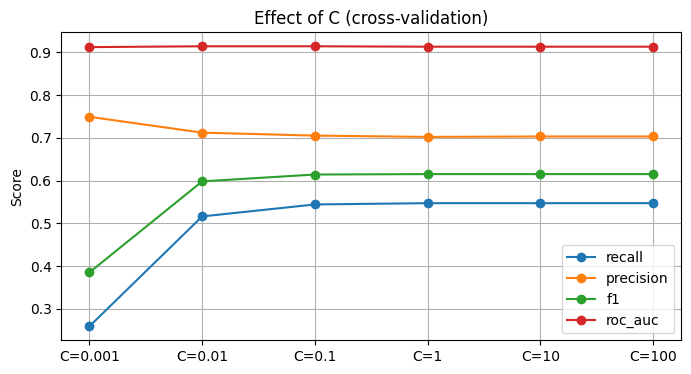

In [35]:
# Plot: effect of C
plt.figure(figsize=(8, 4))
for m in ["recall", "precision", "f1", "roc_auc"]:
    plt.plot(c_df["Setting"], c_df[m], marker="o", label=m)
plt.title("Effect of C (cross-validation)"); plt.ylabel("Score"); plt.legend(); plt.grid(True)
plt.show()

### Interpretation: class_weight

class_weight gives more importance to mistakes on the smaller class (buyers).

- Default (None): precision 0.702, recall 0.547, F1 0.615.
- balanced (buyers weighted about 5.4 times more, because there are about 5.4 non-buyers for every buyer): recall increased to 0.798, but precision fell to 0.550. F1 rose to 0.651.
- Custom weight {0: 1, 1: 3} (buyers weighted 3 times more): recall 0.729, precision 0.617, and the best F1 of 0.668.

This shows the trade-off between precision and recall. Giving buyers more weight helps the model find many more of them (recall rose by about 25 percentage points with balanced weights), but it also creates more false alarms (lower precision). The custom 3x weight gave the best balance between the two.

ROC-AUC stayed about the same (0.913 to 0.918), because class weights mainly move the point at which the model predicts a purchase, similar to changing the decision threshold, rather than changing how well it ranks sessions.

In marketing terms, a higher recall means reaching more real buyers (for example, with a retargeting campaign), while a higher precision means wasting less budget on people who would not buy.

## Step 7: GridSearchCV and Decision Threshold Tuning

In [36]:
pipe = Pipeline([("scaler", StandardScaler()),
                 ("model", LogisticRegression(max_iter=5000, solver="liblinear", random_state=42))])
param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__penalty": ["l1", "l2"],
    "model__class_weight": [None, "balanced", {0: 1, 1: 2}, {0: 1, 1: 3}, {0: 1, 1: 4}]
}
grid = GridSearchCV(pipe, param_grid, cv=cv5, scoring="f1", n_jobs=-1)
grid.fit(X_train_p, y_train)
print("Combinations tested:", len(grid.cv_results_["params"]))
print("Best settings:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 3))
top5 = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score").head(5)
print(top5[["params", "mean_test_score"]].to_string(index=False))

Combinations tested: 40
Best settings: {'model__C': 0.1, 'model__class_weight': {0: 1, 1: 3}, 'model__penalty': 'l1'}
Best CV F1: 0.673
                                                                         params  mean_test_score
 {'model__C': 0.1, 'model__class_weight': {0: 1, 1: 3}, 'model__penalty': 'l1'}         0.672965
{'model__C': 0.01, 'model__class_weight': {0: 1, 1: 4}, 'model__penalty': 'l1'}         0.672650
{'model__C': 0.01, 'model__class_weight': {0: 1, 1: 3}, 'model__penalty': 'l1'}         0.671193
{'model__C': 0.01, 'model__class_weight': {0: 1, 1: 3}, 'model__penalty': 'l2'}         0.670859
  {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l1'}         0.669891


C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


In [37]:
from sklearn.model_selection import cross_val_predict

In [39]:
best_model = grid.best_estimator_
cv_probs = cross_val_predict(best_model, X_train_p, y_train, cv=cv5, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.2, 0.81, 0.05):
    pred = (cv_probs >= t).astype(int)
    rows.append({"threshold": round(t, 2),
                 "precision": round(precision_score(y_train, pred), 3),
                 "recall": round(recall_score(y_train, pred), 3),
                 "f1": round(f1_score(y_train, pred), 3)})
thr_df = pd.DataFrame(rows)
print(thr_df.to_string(index=False))

best_t = thr_df.loc[thr_df["f1"].idxmax(), "threshold"]
print("\nBest threshold (by CV F1):", best_t)

C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty=

 threshold  precision  recall    f1
      0.20      0.398   0.913 0.554
      0.25      0.448   0.883 0.594
      0.30      0.501   0.847 0.630
      0.35      0.549   0.800 0.651
      0.40      0.585   0.773 0.666
      0.45      0.603   0.750 0.669
      0.50      0.621   0.735 0.673
      0.55      0.631   0.710 0.668
      0.60      0.643   0.677 0.660
      0.65      0.658   0.655 0.656
      0.70      0.668   0.616 0.641
      0.75      0.684   0.564 0.618
      0.80      0.706   0.512 0.593

Best threshold (by CV F1): 0.5


C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


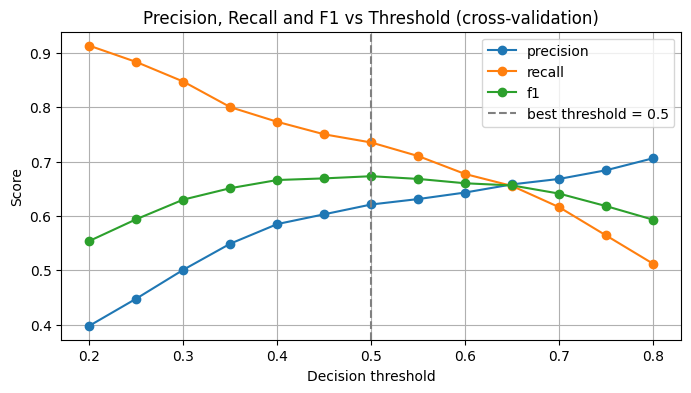

In [40]:
plt.figure(figsize=(8, 4))
for m in ["precision", "recall", "f1"]:
    plt.plot(thr_df["threshold"], thr_df[m], marker="o", label=m)
plt.axvline(best_t, color="gray", linestyle="--", label=f"best threshold = {best_t}")
plt.xlabel("Decision threshold"); plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Threshold (cross-validation)")
plt.legend(); plt.grid(True); plt.show()

### Interpretation: Decision Threshold

I tested thresholds from 0.20 to 0.80 using cross-validated probabilities on the training data, so the test set was not used to choose the threshold.

- At a low threshold (0.20), the model predicts a purchase very easily. It finds 91.3% of buyers (recall), but only 39.8% of its purchase predictions are correct (precision).
- At a high threshold (0.80), it predicts a purchase only when very confident. Precision rises to 70.6%, but recall falls to 51.2%.
- F1 is highest at 0.50 (0.673). Because the class weight (buyers counted 3 times more) had already shifted the model towards predicting purchases, the default threshold was already the best balance.
- F1 stays between about 0.66 and 0.67 for thresholds from 0.40 to 0.60, so the threshold can be adjusted for business needs without losing much overall performance.

Business choice:
- A lower threshold such as 0.35 (recall 0.80, precision 0.55) suits low-cost actions like retargeting ads, where reaching more real buyers is worth some wasted impressions.
- A higher threshold such as 0.65 (precision 0.66, recall 0.66) suits costly actions like large discounts, where each wrong prediction wastes money.

I will use 0.50, the threshold with the best F1-score.

## Step 8: Final Model Evaluation on the Test Set

In [41]:
final_model = grid.best_estimator_
final_prob = final_model.predict_proba(X_test_p)[:, 1]
final_pred = (final_prob >= best_t).astype(int)

def scores(y_true, pred, prob):
    return {"Accuracy": accuracy_score(y_true, pred), "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred), "F1": f1_score(y_true, pred), "ROC-AUC": roc_auc_score(y_true, prob)}

compare = pd.DataFrame([{"Model": "Baseline (default)", **scores(y_test, y_pred, y_prob)},
                        {"Model": "Tuned (C=0.1, L1, weight 1:3)", **scores(y_test, final_pred, final_prob)}]).round(3)
print(compare.to_string(index=False))
print("\n", classification_report(y_test, final_pred, target_names=["No purchase", "Purchase"]))

                        Model  Accuracy  Precision  Recall    F1  ROC-AUC
           Baseline (default)     0.896      0.702   0.586 0.639    0.921
Tuned (C=0.1, L1, weight 1:3)     0.890      0.623   0.751 0.681    0.925

               precision    recall  f1-score   support

 No purchase       0.95      0.92      0.93      2059
    Purchase       0.62      0.75      0.68       382

    accuracy                           0.89      2441
   macro avg       0.79      0.83      0.81      2441
weighted avg       0.90      0.89      0.89      2441



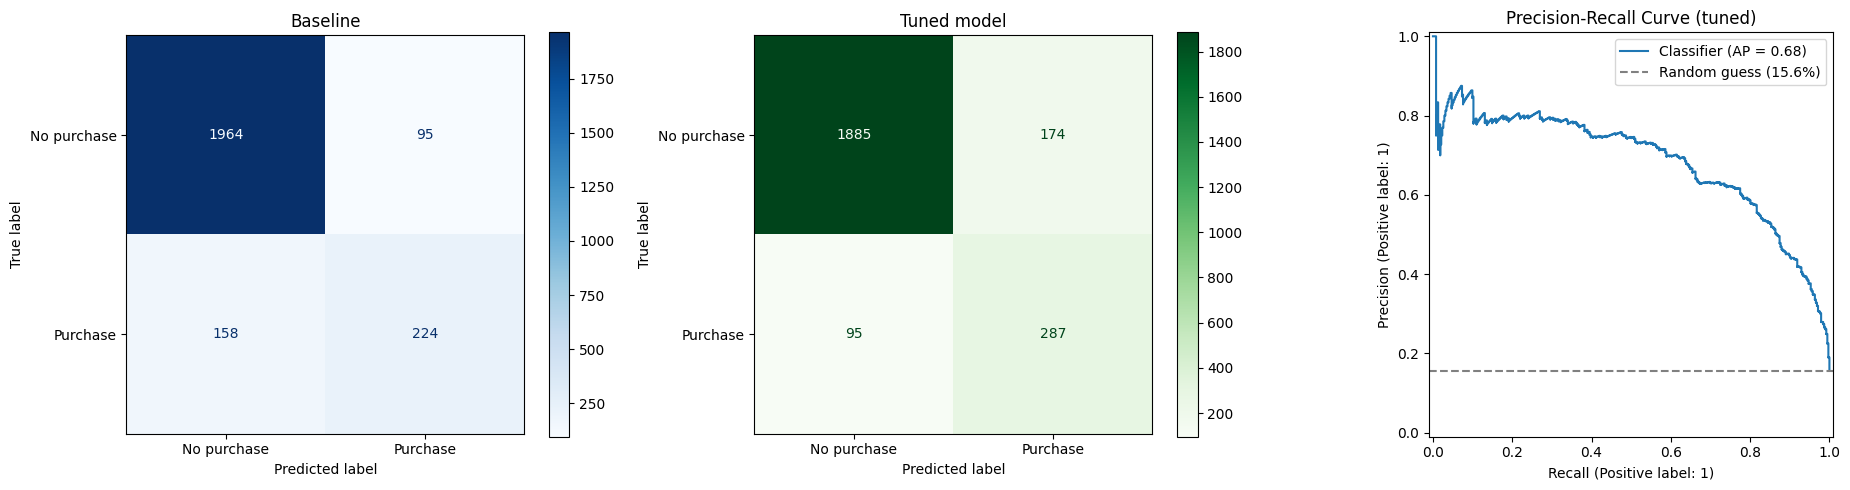

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["No purchase", "Purchase"]).plot(cmap="Blues", ax=axes[0])
axes[0].set_title("Baseline")
ConfusionMatrixDisplay(confusion_matrix(y_test, final_pred), display_labels=["No purchase", "Purchase"]).plot(cmap="Greens", ax=axes[1])
axes[1].set_title("Tuned model")
PrecisionRecallDisplay.from_predictions(y_test, final_prob, ax=axes[2])
axes[2].axhline(y_test.mean(), color="gray", linestyle="--", label="Random guess (15.6%)")
axes[2].set_title("Precision-Recall Curve (tuned)"); axes[2].legend()
plt.tight_layout(); plt.show()

### Interpretation: Final Evaluation on the Test Set

Baseline vs tuned model:
- The tuned model (C = 0.1, L1 penalty, buyers weighted 3 times more, threshold 0.50) found 287 of the 382 buyers, compared to 224 for the baseline. That is 63 more buyers identified.
- Missed buyers (false negatives) dropped from 158 to 95.
- False alarms (false positives) rose from 95 to 174, because the model now predicts a purchase more readily.
- Recall improved from 0.586 to 0.751, while precision dropped from 0.702 to 0.623. F1 improved from 0.639 to 0.681, so the overall balance is better.
- Accuracy dropped slightly, from 0.896 to 0.890. This shows why accuracy can be misleading on imbalanced data: the tuned model is more useful because it finds many more buyers, even though its accuracy is a little lower.
- ROC-AUC stayed about the same (0.921 vs 0.925), because tuning mainly changed where the model draws the line between buyer and non-buyer, not how well it ranks sessions.
- The test F1 (0.681) is close to the cross-validation F1 (0.673), so the tuning generalized well to new data.

Classification report (tuned model):
- No purchase: precision 0.95, recall 0.92.
- Purchase: precision 0.62, recall 0.75. When the model

## Step 9: Predicting the Outcome for a New Session

In [44]:
new_session = X_test_p.iloc[[5]]           # one session from the test set, same columns as training
print("Original (unprepared) values:")
display(X_test.iloc[[5]])

prob = final_model.predict_proba(new_session)[0, 1]
print(f"Predicted purchase probability: {prob:.1%}")
print("Prediction:", "Purchase" if prob >= best_t else "No purchase")
print("Actual:", "Purchase" if y_test.iloc[5] == 1 else "No purchase")

Original (unprepared) values:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
9878,11,250.25,0,0.0,169,8276.292565,0.002406,0.016052,8.174729,0.0,Nov,4,1,1,8,Returning_Visitor,True


Predicted purchase probability: 91.7%
Prediction: Purchase
Actual: No purchase


### Interpretation: Prediction for a New Session

I took one session from the test set (row 5) and kept it as a one-row table with the same 32 columns as the training data, so it has the same structure the model was trained on.

- Predicted purchase probability: 91.7%
- Prediction (threshold 0.50): Purchase
- Actual result: No purchase

This is a false positive: the model was very confident that this visitor would buy, but they did not. The visitor's behaviour likely looked like a typical buyer's, for example visiting pages that usually lead to purchases (high PageValues) and viewing many product pages. In real online shopping, this often happens when people add items to the cart and then leave without paying (cart abandonment), or plan to buy later.

This example shows that even a model with a high ROC-AUC can be confidently wrong for individual visitors. In practice, a session like this could be a good target for a reminder email or a small discount, because the visitor showed strong buying signals.

## Step 10: Interpreting the Model - Odds Ratios

Features removed by L1 (coefficient = 0): ['Administrative', 'ProductRelated_Duration', 'SpecialDay', 'Month_Oct', 'VisitorType_Other']


,coefficient,odds_ratio
ExitRates,-0.431,0.650
Month_May,-0.390,0.677
Month_Mar,-0.244,0.784
Month_Dec,-0.214,0.807
Month_Feb,-0.163,0.849
TrafficType_13,-0.123,0.884
VisitorType_Returning_Visitor,-0.112,0.894
Administrative_Duration,-0.052,0.949
Informational_Duration,-0.045,0.956
Month_June,-0.025,0.975


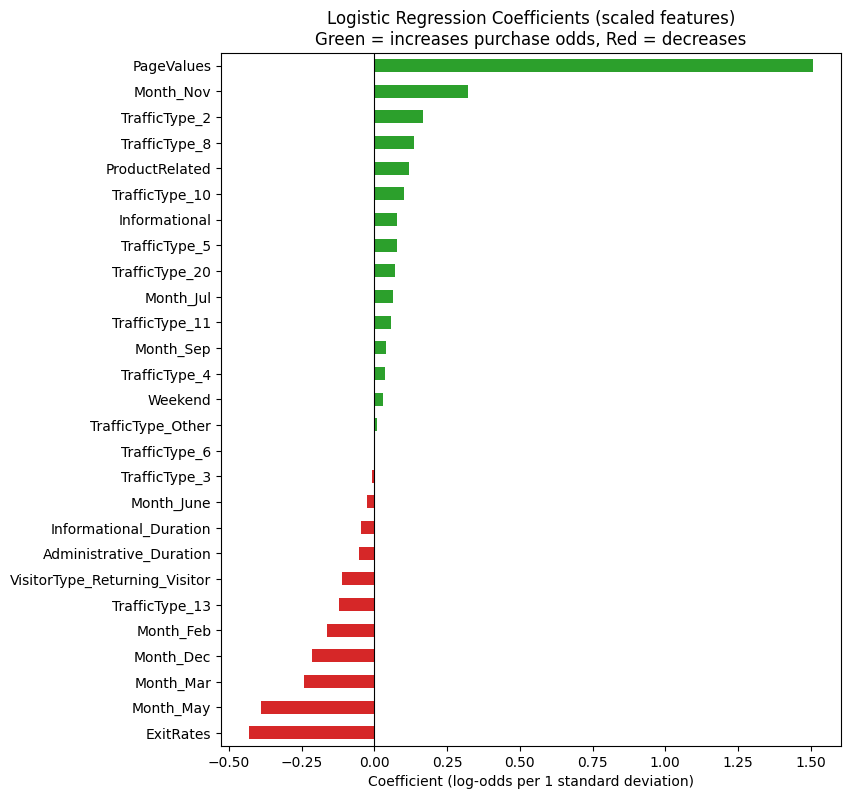

In [45]:
coefs = pd.Series(final_model.named_steps["model"].coef_[0], index=X_train_p.columns)
odds = pd.DataFrame({"coefficient": coefs, "odds_ratio": np.exp(coefs)}).sort_values("coefficient")
print("Features removed by L1 (coefficient = 0):", list(coefs[coefs == 0].index))
display(odds.round(3))

odds_nonzero = odds[odds["coefficient"] != 0]
colors = ["tab:green" if c > 0 else "tab:red" for c in odds_nonzero["coefficient"]]
odds_nonzero["coefficient"].plot(kind="barh", figsize=(8, 9), color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression Coefficients (scaled features)\nGreen = increases purchase odds, Red = decreases")
plt.xlabel("Coefficient (log-odds per 1 standard deviation)")
plt.show()

### Interpretation: Odds Ratios

The odds ratio shows how the odds of a purchase change when a feature increases. An odds ratio above 1 increases the chance of buying, and below 1 decreases it. Because the features were scaled, each value shows the effect of a 1 standard deviation increase, so the sizes can be compared. Month, visitor type, and traffic type are compared to their baseline categories (August, new visitors, and traffic type 1).

Features that increase the chance of buying:
- PageValues has by far the strongest effect (odds ratio 4.52). A 1 standard deviation increase makes the odds of buying about 4.5 times higher. Visitors who view pages that usually lead to purchases are much more likely to buy.
- November (1.38) has 38% higher purchase odds than August, matching the holiday shopping season.
- Traffic type 2 (1.18) has 18% higher odds than traffic type 1.
- Viewing more product pages (1.13) also slightly increases the odds.

Features that decrease the chance of buying:
- ExitRates (0.65): a higher exit rate reduces the odds of buying by about 35%. Visitors who view pages that people often leave from are less likely to buy.
- May (0.68) has 32% lower odds than August, which matches the EDA, where May had a lot of traffic but a low conversion rate. March, December, and February also have lower odds.
- Returning visitors (0.89) have about 11% lower odds than new visitors, matching the EDA (14.2% vs 24.1% conversion).
- Traffic type 13 (0.88) is a weaker traffic source.

Features removed by L1:
L1 regularization set five coefficients to exactly zero: Administrative, ProductRelated_Duration, SpecialDay, October, and the "Other" visitor type. Their information was already covered by other features. For example, time spent on product pages overlaps strongly with the number of product pages viewed (correlation 0.85), so the model kept only one of them.

Marketing insights:
- Getting visitors to high-value pages (product and cart pages) matters most.
- Pages with high exit rates should be reviewed and improved.
- November is the best month to invest in campaigns, while May brings traffic that converts poorly.
- New visitors convert well, so acquisition campaigns are worthwhile, while returning visitors may need extra encouragement, such as reminders or offers.

In [46]:
# How much does the model depend on PageValues?
no_pv = Pipeline([("scaler", StandardScaler()),
                  ("model", LogisticRegression(max_iter=5000, solver="liblinear", C=0.1, penalty="l1",
                                               class_weight={0: 1, 1: 3}, random_state=42))])
cv_with = cross_validate(final_model, X_train_p, y_train, cv=cv5, scoring=["f1", "roc_auc"])
cv_without = cross_validate(no_pv, X_train_p.drop(columns="PageValues"), y_train, cv=cv5, scoring=["f1", "roc_auc"])
print(f"With PageValues    - CV F1: {cv_with['test_f1'].mean():.3f} | CV ROC-AUC: {cv_with['test_roc_auc'].mean():.3f}")
print(f"Without PageValues - CV F1: {cv_without['test_f1'].mean():.3f} | CV ROC-AUC: {cv_without['test_roc_auc'].mean():.3f}")



C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty=

With PageValues    - CV F1: 0.673 | CV ROC-AUC: 0.918
Without PageValues - CV F1: 0.377 | CV ROC-AUC: 0.747


C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\patel\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty=

### Interpretation: How Much the Model Depends on PageValues

I compared the tuned model with and without PageValues, using 5-fold cross-validation on the training data:
- With PageValues: F1 = 0.673, ROC-AUC = 0.918
- Without PageValues: F1 = 0.377, ROC-AUC = 0.747

Removing this one feature cut the F1-score almost in half and reduced ROC-AUC from excellent (0.92) to fair (0.75). The model relies very heavily on PageValues.

This makes sense, because Google Analytics calculates PageValues using purchases: a page gets a higher value when it often appears before a transaction. Pages like the shopping cart or checkout steps get high values, so a session with a high PageValue has often already moved close to buying. This makes PageValues very close to the answer the model is trying to predict, which is a form of partial data leakage.

What this means in practice:
- If the goal is to analyze completed sessions, using PageValues is fine and gives strong results.
- If the goal is to predict buyers early in a visit (for example, to show a discount pop-up), PageValues may not be known yet. In that case, the realistic performance is closer to the model without it (ROC-AUC 0.75), which is still much better than random guessing (0.5), but far from 0.92.

The other features (such as exit rates, product page activity, month, and visitor type) still carry useful information on their own, but PageValues is the strongest signal by far.